# 영화 관객수 예측 — test 데이터 EDA

ESAA YB 미니 프로젝트(3)

미니 프로젝트(1)에서 만든 EDA 노트북 네 개(총 330셀)에는 **`test`라는 단어가 한 번도 나오지 않는다.**
그때는 데이터를 이해하는 것이 목적이라 train만 봐도 됐지만, 이제는 test에 예측값을 내야 한다.
**예측을 내려면 입력이 어떻게 생겼는지 알아야 한다.**

이 노트북에서 보는 것은 test의 **정답이 아니라 입력 변수**다. 목적은 하나다 —
**train/test에 공통으로 적용할 전처리 규칙을 정하는 것.**

| 볼 것 | 왜 |
|---|---|
| 결측의 정체 | 채울 것인지 의미가 있는 값인지 |
| 이상값·입력 오류 | test에 있는 오류는 그대로 점수에 반영된다 |
| train에 없는 범주 | 인코딩 방식을 결정한다 |
| 분포 차이 | train에서 배운 것이 test에 통하는지 |
| 표기 흔들림 | 같은 배급사가 다른 값으로 잡히는지 |

마지막에 결론을 **공통 전처리 규칙** 표로 정리한다.


In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# 한글 글꼴 — seaborn 스타일을 먼저 적용해야 한다.
# sns.set_style()이 rcParams를 초기화해서, 순서가 바뀌면 글꼴 설정이 지워진다.
sns.set_style('whitegrid')

import matplotlib.font_manager as fm
_have = {f.name for f in fm.fontManager.ttflist}
for _f in ('Malgun Gothic', 'NanumGothic', 'AppleGothic', 'Gulim'):
    if _f in _have:
        mpl.rcParams['font.family'] = _f
        print('한글 글꼴:', _f)
        break
else:
    print('한글 글꼴을 찾지 못했다. Colab이면 아래를 실행한 뒤 런타임을 다시 시작한다.')
    print('  !apt-get install -y fonts-nanum && fc-cache -fv')
mpl.rcParams['axes.unicode_minus'] = False

RAW = 'https://raw.githubusercontent.com/sjlee53/ESAA-submission/YB/project/1/data/'
LOCAL = os.path.join('..', '1', 'data')

def read(name):
    p = os.path.join(LOCAL, name)
    if os.path.exists(p):
        return pd.read_csv(p)
    return pd.read_csv(RAW + name)

train = read('movies_train.csv')
test = read('movies_test.csv')
print('train', train.shape, ' test', test.shape)


한글 글꼴: Malgun Gothic
train (600, 12)  test (243, 11)


## 1. 두 데이터의 모양

train은 600행 × 12열, test는 243행 × 11열이다. 차이 나는 한 열이 타깃 `box_off_num`이다.


In [2]:
print('train에만 있는 열:', set(train.columns) - set(test.columns))
print()
info = pd.DataFrame({
    'dtype': train.dtypes.astype(str),
    'train_결측': train.isna().sum(),
    'test_결측': test.reindex(columns=train.columns).isna().sum(),
    'train_고유값': train.nunique(),
    'test_고유값': test.reindex(columns=train.columns).nunique(),
})
info


train에만 있는 열: {'box_off_num'}



,dtype,train_결측,test_결측,train_고유값,test_고유값
title,object,0,0,600,243
distributor,object,0,0,169,93
genre,object,0,0,12,12
release_time,object,0,0,330,182
time,int64,0,0,86,70
screening_rat,object,0,0,4,4
director,object,0,0,472,220
dir_prev_bfnum,float64,330,136,245,103
dir_prev_num,int64,0,0,6,7
num_staff,int64,0,0,296,165


## 2. 결측은 결측이 아니다

`dir_prev_bfnum`(감독의 이전 작품 평균 관객수)에 train 330건, test 136건의 결측이 있다.
비율로는 train 55%, test 56%로 거의 같다. **이건 값이 빠진 것이 아니다.**


In [3]:
for name, df in [('train', train), ('test', test)]:
    na = df['dir_prev_bfnum'].isna()
    print('{:5s} 결측 {:3d}건 중 dir_prev_num == 0 인 행: {:3d}건 ({:.0%})'
          .format(name, na.sum(), (na & (df['dir_prev_num'] == 0)).sum(),
                  (na & (df['dir_prev_num'] == 0)).sum() / na.sum()))
    print('      dir_prev_num == 0 인데 값이 있는 행: {}건'
          .format(((df['dir_prev_num'] == 0) & ~na).sum()))


train 결측 330건 중 dir_prev_num == 0 인 행: 330건 (100%)
      dir_prev_num == 0 인데 값이 있는 행: 0건
test  결측 136건 중 dir_prev_num == 0 인 행: 136건 (100%)
      dir_prev_num == 0 인데 값이 있는 행: 0건


**결측 100%가 `dir_prev_num == 0`인 행이고, 그 반대도 성립한다.**
"감독의 이전 작품이 없으니 평균 관객수도 없다"는 뜻이다. 기록 누락이 아니라 **사실의 표현**이다.

그래서 평균이나 중앙값으로 채우면 안 된다. 신인 감독에게 "기성 감독의 평균 실적"을 주는 셈이 된다.
**0으로 채우고, 대신 `has_prev`(이전작 유무) 변수를 따로 만드는 것**이 맞다.
5장에서 주택 가격의 `PoolQC` 결측 1,453건이 "수영장이 없다"는 뜻이었던 것과 같은 종류다.


In [4]:
# 이전작 유무로 나눠 본 관객수 (train)
g = train.groupby(train['dir_prev_num'] > 0)['box_off_num'].agg(['count', 'median', 'mean'])
g.index = ['이전작 없음', '이전작 있음']
g.round(0)


,count,median,mean
이전작 없음,330,3402.0,349204.0
이전작 있음,270,222258.0,1146932.0


## 3. 입력 오류 — test에 있는 오류는 그대로 점수가 된다

train에서 배운 전처리는 test에도 똑같이 적용되므로, **test의 이상값은 반드시 먼저 봐야 한다.**


In [5]:
num_cols = ['time', 'num_staff', 'num_actor', 'dir_prev_num', 'dir_prev_bfnum']
pd.concat([train[num_cols].describe().T.add_prefix('train_')[['train_min', 'train_50%', 'train_max']],
           test[num_cols].describe().T.add_prefix('test_')[['test_min', 'test_50%', 'test_max']]],
          axis=1).round(1)


,train_min,train_50%,train_max,test_min,test_50%,test_max
time,45.0,100.0,180.0,40.0,104.0,2015.0
num_staff,0.0,82.5,869.0,0.0,105.0,776.0
num_actor,0.0,3.0,25.0,0.0,3.0,16.0
dir_prev_num,0.0,0.0,5.0,0.0,0.0,6.0
dir_prev_bfnum,1.0,478423.6,17615314.0,34.0,493120.0,6173099.5


In [6]:
# train 범위를 벗어난 test 행 찾기
for c in num_cols:
    lo, hi = train[c].min(), train[c].max()
    bad = test[(test[c] < lo) | (test[c] > hi)]
    if len(bad):
        print('### {} : train 범위 [{:,.0f}, {:,.0f}] 밖 {}건'.format(c, lo, hi, len(bad)))
        print(bad[['title', 'genre', c, 'num_staff', 'release_time']].to_string(), end='\n\n')


### time : train 범위 [45, 180] 밖 3건
        title   genre  time  num_staff release_time
33     카페 느와르     드라마   198        230   2010-12-30
140  오하이오 삿포로  멜로/로맨스    40          1   2013-01-03
224  슈퍼레이서 엔지   애니메이션  2015          4   2015-09-10

### dir_prev_num : train 범위 [0, 5] 밖 1건
            title genre  dir_prev_num  num_staff release_time
183  더 테너 리리코 스핀토   드라마             6        194   2014-12-31



train 범위를 벗어난 행이 네 건 나왔는데, **셋은 정상이고 하나만 오류다.**

- 「카페 느와르」 198분, 「오하이오 삿포로」 40분 — train 범위(45~180분)를 조금 벗어났을 뿐
  **실제로 있을 수 있는 상영시간**이다. 그대로 둔다.
- 「더 테너 리리코 스핀토」의 `dir_prev_num` 6 — train 최대가 5일 뿐 이상한 값이 아니다. 그대로 둔다.
- **「슈퍼레이서 엔지」의 상영시간 2015분 — 이건 오류다.** 개봉일이 2015-09-10이니
  **상영시간 칸에 개봉연도가 들어갔다.** 2015분은 33시간이다.

마지막 한 건은 반드시 고쳐야 한다. 243편짜리 RMSE에서 한 편의 오차는 `오차 ÷ √243`만큼
점수에 그대로 반영된다. **같은 장르(애니메이션)의 train 중앙값으로 바꾼다.**

"범위 밖"과 "오류"는 다르다는 것이 이 대목의 요점이다. 자동으로 걸러내지 말고 행을 직접 봐야 한다.


In [7]:
print('애니메이션 상영시간 (train)')
print(train[train.genre == '애니메이션']['time'].describe().round(1).to_string())
print()
print('대체값:', train[train.genre == '애니메이션']['time'].median(), '분')


애니메이션 상영시간 (train)
count     21.0
mean      82.6
std        9.8
min       62.0
25%       78.0
50%       83.0
75%       88.0
max      100.0

대체값: 83.0 분


### train에도 이상한 행이 있다


In [8]:
# 이전작 평균 관객수는 1,700만인데 정작 본인 영화는 8명?
train.nlargest(5, 'dir_prev_bfnum')[
    ['title', 'director', 'genre', 'dir_prev_num', 'dir_prev_bfnum', 'num_staff', 'box_off_num']]


,title,director,genre,dir_prev_num,dir_prev_bfnum,num_staff,box_off_num
338,타부 : 금지된 사랑,고구마,멜로/로맨스,1,17615314.0,27,8
214,초능력자,김민석,SF,2,8801639.0,500,2130645
16,써니,강형철,코미디,1,8223342.0,572,7453715
118,라스트 갓파더,심형래,코미디,1,7855474.0,31,2541603
409,타짜-신의 손,강형철,드라마,2,7838528.5,583,4015364


**「타부 : 금지된 사랑」의 `dir_prev_bfnum`이 17,615,314인데 본인 영화의 관객수는 8명이다.**
이 값은 명량의 관객수(약 1,760만)와 사실상 같다. 감독명 '고구마'에 다른 감독의 기록이 섞여 들어간
데이터 오류로 보인다.

train 쪽 오류라 점수에 직접 영향은 없지만, **학습할 때 이 한 행이 `dir_prev_bfnum`과 관객수의 관계를
정반대로 가르친다.** 회귀에서 극단값 하나가 미치는 영향은 5.10 실습에서 이미 본 적이 있다
(거주 면적이 큰데 가격이 낮은 2건을 지우자 RMSE가 눈에 띄게 좋아졌다).


In [9]:
# 0인 값들 — 결측이 아니라 '없음'인지 확인
for c in ['num_staff', 'num_actor']:
    print('{:10s} == 0 : train {:3d}건 / test {:3d}건'
          .format(c, (train[c] == 0).sum(), (test[c] == 0).sum()))
print()
print('num_staff == 0 인 train 영화의 관객수 중앙값: {:,.0f}  (전체 중앙값 {:,.0f})'
      .format(train[train.num_staff == 0].box_off_num.median(), train.box_off_num.median()))
print('num_actor == 0 인 train 영화의 관객수 중앙값: {:,.0f}'
      .format(train[train.num_actor == 0].box_off_num.median()))


num_staff  == 0 : train  32건 / test  15건
num_actor  == 0 : train   9건 / test   4건

num_staff == 0 인 train 영화의 관객수 중앙값: 996  (전체 중앙값 12,591)
num_actor == 0 인 train 영화의 관객수 중앙값: 862


`num_staff = 0`은 "스태프가 없다"가 아니라 **스태프 정보가 기록되지 않은 소규모 영화**로 보인다.
이들의 관객수 중앙값이 996명으로 전체 중앙값 12,591명보다 훨씬 작다. **0이라는 값 자체가 신호다.**
따로 채우지 말고 그대로 두되, `is_micro`(스태프 0) 같은 변수를 만들어 볼 수 있다.


## 4. 분포는 비슷한가

train에서 배운 패턴이 test에 통하려면 입력 분포가 비슷해야 한다.


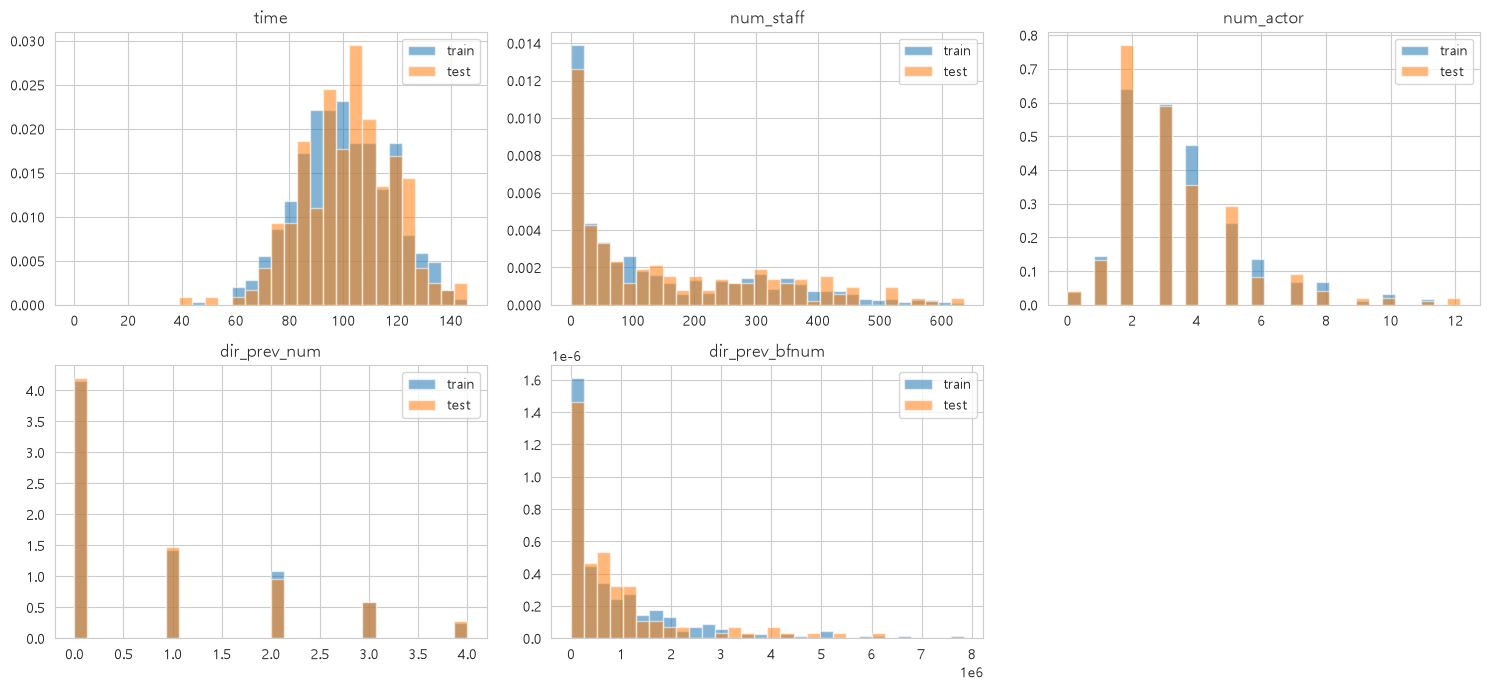

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), num_cols):
    lo, hi = 0, np.nanpercentile(pd.concat([train[c], test[c]]), 99)
    ax.hist(train[c].dropna(), bins=30, range=(lo, hi), alpha=.55, density=True, label='train')
    ax.hist(test[c].clip(upper=hi).dropna(), bins=30, range=(lo, hi), alpha=.55, density=True, label='test')
    ax.set_title(c)
    ax.legend()
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()


In [11]:
pd.DataFrame({
    'train_평균': train[num_cols].mean(),
    'test_평균': test[num_cols].mean(),
    'train_중앙': train[num_cols].median(),
    'test_중앙': test[num_cols].median(),
}).round(1)


,train_평균,test_평균,train_중앙,test_중앙
time,100.9,109.8,100.0,104.0
num_staff,151.1,159.3,82.5,105.0
num_actor,3.7,3.5,3.0,3.0
dir_prev_num,0.9,0.9,0.0,0.0
dir_prev_bfnum,1050442.9,891669.5,478423.6,493120.0


**분포가 거의 같다.** test의 `num_staff` 중앙값이 105로 train의 82.5보다 조금 크지만
평균(151 vs 159)은 비슷하다. **분포 차이 때문에 모델이 망가질 걱정은 하지 않아도 된다.**

이건 중요한 확인이다. 교차검증 점수를 리더보드의 대리 지표로 믿어도 된다는 뜻이기 때문이다.


## 5. 범주형 — 여기가 진짜 문제다


In [12]:
rows = []
for c in ['genre', 'screening_rat', 'distributor', 'director']:
    seen = set(train[c])
    unseen = ~test[c].isin(seen)
    rows.append({
        '변수': c,
        'train 고유값': train[c].nunique(),
        'test 고유값': test[c].nunique(),
        'test에만 있는 값': test.loc[unseen, c].nunique(),
        'test 행 중 미등장 비율': '{:.0%}'.format(unseen.mean()),
    })
pd.DataFrame(rows)


,변수,train 고유값,test 고유값,test에만 있는 값,test 행 중 미등장 비율
0,genre,12,12,0,0%
1,screening_rat,4,4,0,0%
2,distributor,169,93,35,15%
3,director,472,220,142,63%


**감독은 test 243편 중 63%가 train에 없는 사람이 찍은 영화다.** 감독 타깃 인코딩이 실패하는 이유가
여기 있다 — train에 없으면 전체 평균으로 채울 수밖에 없는데, 그러면 세 편 중 두 편이 같은 값을 받는다.
변수가 정보를 주지 못하고 노이즈만 는다. 실제로 감독 타깃 인코딩을 넣으면 세 모델 모두
교차검증 RMSE가 12% 나빠진다(144만 → 162만).

**배급사는 미등장 비율이 15%로 훨씬 낮다.** 게다가 **배급사는 규모 자체가 신호**라서,
이름을 몰라도 "몇 편을 낸 배급사인가"는 알 수 있다. 빈도 인코딩이 잘 작동하는 이유다.

장르와 등급은 test에만 있는 값이 하나도 없다. 원-핫 인코딩을 그대로 쓰면 된다.


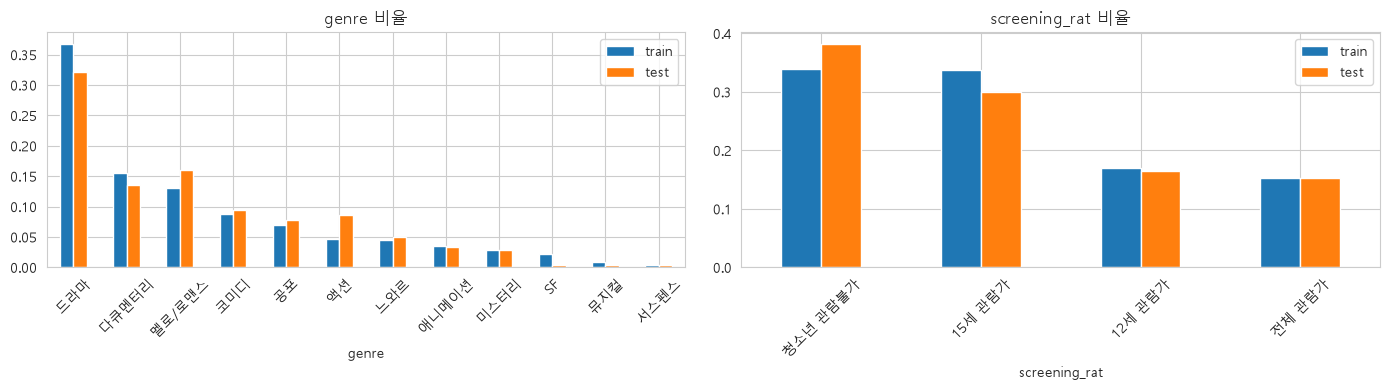

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c in zip(axes, ['genre', 'screening_rat']):
    comp = pd.concat([train[c].value_counts(normalize=True).rename('train'),
                      test[c].value_counts(normalize=True).rename('test')], axis=1).fillna(0)
    comp.plot.bar(ax=ax, rot=45)
    ax.set_title('{} 비율'.format(c)); ax.set_ylabel('')
plt.tight_layout(); plt.show()


In [14]:
comp = pd.concat([train.genre.value_counts(normalize=True).rename('train'),
                  test.genre.value_counts(normalize=True).rename('test')], axis=1).fillna(0)
comp['차이(%p)'] = ((comp.test - comp.train) * 100).round(1)
comp.round(3).sort_values('차이(%p)')


,train,test,차이(%p)
genre,,,
드라마,0.368,0.321,-4.7
다큐멘터리,0.155,0.136,-1.9
SF,0.022,0.004,-1.8
뮤지컬,0.008,0.004,-0.4
애니메이션,0.035,0.033,-0.2
미스터리,0.028,0.029,0.0
서스펜스,0.003,0.004,0.1
느와르,0.045,0.049,0.4
코미디,0.088,0.095,0.6


장르 비율은 대체로 비슷하지만 **액션이 test에 4%p 많고 SF는 1.8%p 적다.**
액션은 평균 관객수가 큰 장르라 이 차이가 점수에 영향을 준다.


In [15]:
train.groupby('genre')['box_off_num'].agg(['count', 'median', 'mean']).sort_values('mean', ascending=False).round(0)


,count,median,mean
genre,,,
느와르,27,1646142.0,2263695.0
액션,28,1147846.0,2203974.0
SF,13,9323.0,1788346.0
코미디,53,210775.0,1193914.0
드라마,221,7173.0,625690.0
공포,42,179810.0,590833.0
미스터리,17,3199.0,527548.0
멜로/로맨스,78,3653.0,425968.0
애니메이션,21,23802.0,181927.0


## 6. 배급사 이름 표기가 흔들린다

`(주)NEW`, `CJ 엔터테인먼트`처럼 괄호와 공백이 섞여 있다.
**같은 회사가 다른 값으로 잡히면 빈도 인코딩이 그만큼 쪼개진다.**


In [16]:
import re

def norm(s):
    s = re.sub(r'\(주\)|㈜|주식회사', '', str(s))
    s = re.sub(r'[\s\-\.]', '', s)
    return s.strip()

full = pd.concat([train['distributor'], test['distributor']], ignore_index=True)
m = pd.DataFrame({'원본': full, '정규화': full.map(norm)})
dup = m.groupby('정규화')['원본'].nunique()
dup = dup[dup > 1].sort_values(ascending=False)
print('정규화하면 합쳐지는 배급사: {}개'.format(len(dup)))
print('전체 고유 배급사 {} -> {}'.format(full.nunique(), m['정규화'].nunique()))
print()
for k in dup.index[:10]:
    print('  {:20s} <- {}'.format(k, sorted(m.loc[m['정규화'] == k, '원본'].unique())))


정규화하면 합쳐지는 배급사: 11개
전체 고유 배급사 204 -> 191

  디씨드                  <- ['(주)디씨드', '디 씨드', '디씨드']
  시네마달                 <- ['(주)시네마달', '시네마 달', '시네마달']
  CGV아트하우스             <- ['CGV 아트하우스', 'CGV아트하우스']
  드림팩트엔터테인먼트           <- ['(주)드림팩트엔터테인먼트', '드림팩트 엔터테인먼트']
  NEW                  <- ['(주)NEW', 'NEW']
  마운틴픽쳐스               <- ['(주)마운틴픽쳐스', '마운틴픽쳐스']
  리틀빅픽처스               <- ['(주)리틀빅픽처스', '리틀빅픽처스']
  마인스엔터테인먼트            <- ['(주)마인스 엔터테인먼트', '(주)마인스엔터테인먼트']
  싸이더스FNH              <- ['싸이더스 FNH', '싸이더스FNH']
  에이원엔터테인먼트            <- ['(주)에이원 엔터테인먼트', '에이원 엔터테인먼트']


표기만 정리해도 배급사 고유값이 줄어든다. **같은 회사의 작품 수가 합쳐지므로 빈도 인코딩이 정확해진다.**


## 7. test의 대작들

이번 과제에서 점수를 좌우하는 것은 평범한 영화가 아니라 **몇 편의 흥행작**이다.
test에서 규모가 큰 영화가 어떤 것들인지 본다.


In [17]:
test.nlargest(10, 'num_staff')[
    ['title', 'genre', 'screening_rat', 'time', 'num_staff', 'num_actor',
     'dir_prev_num', 'dir_prev_bfnum', 'release_time']]


,title,genre,screening_rat,time,num_staff,num_actor,dir_prev_num,dir_prev_bfnum,release_time
178,명량,액션,15세 관람가,128,776,3,2,4.781084e+06,2014-07-30
179,군도: 민란의 시대,액션,15세 관람가,137,685,2,1,7.195870e+05,2014-07-23
229,베테랑,액션,15세 관람가,123,579,4,3,9.746900e+04,2015-08-05
184,기술자들,느와르,15세 관람가,116,564,6,1,1.646142e+06,2014-12-24
216,장수상회,드라마,12세 관람가,112,552,4,2,8.685915e+05,2015-04-09
197,살인의뢰,느와르,청소년 관람불가,102,520,3,0,NaN,2015-03-12
15,포화 속으로,액션,12세 관람가,120,517,4,2,9.555395e+05,2010-06-16
158,우는 남자,액션,청소년 관람불가,116,514,2,2,4.016688e+06,2014-06-04
161,표적,액션,15세 관람가,98,512,6,1,1.634192e+06,2014-04-30
212,간신,드라마,청소년 관람불가,131,510,5,3,1.711110e+06,2015-05-21


train num_staff >= 500 : 23편
count          23.0
mean      4045554.0
std       3933553.0
min        317505.0
25%       1510612.0
50%       2130645.0
75%       6816190.0
max      14262766.0



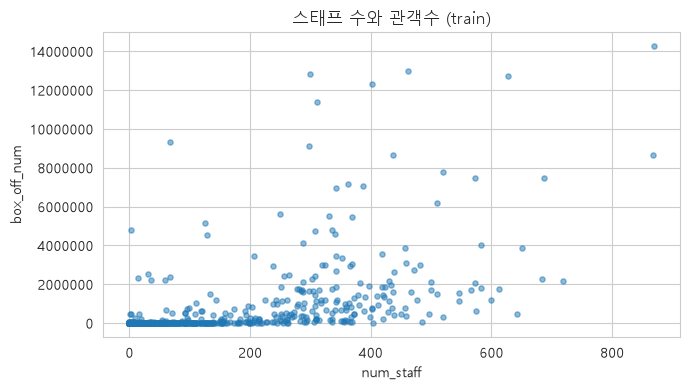

In [18]:
# train에서 비슷한 규모의 영화들은 실제로 얼마나 들었나
big = train[train.num_staff >= 500]
print('train num_staff >= 500 : {}편'.format(len(big)))
print(big['box_off_num'].describe().round(0).to_string())
print()
plt.figure(figsize=(7, 4))
plt.scatter(train.num_staff, train.box_off_num, s=14, alpha=.5)
plt.xlabel('num_staff'); plt.ylabel('box_off_num'); plt.title('스태프 수와 관객수 (train)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout(); plt.show()


**스태프 500명 이상인 23편의 관객수가 31만부터 1,426만까지 흩어져 있다.**
규모가 크다는 것은 알 수 있어도 **얼마나 흥행했는지는 알 수 없다.**

test에서 `num_staff`가 가장 큰 「명량」(776명)과 「베테랑」(579명)이 그 예다.
특히 베테랑은 `dir_prev_bfnum`이 97,469로 기록돼 있어서, 모델이 보기에는
"감독 이전작이 10만 명도 안 든 액션 영화"다. 주어진 변수만으로는 낮게 볼 수밖에 없다.

**이 한계를 인정하고 가거나, 외부 공개 데이터로 감독·배우의 실제 이력을 보강하거나 둘 중 하나다.**


## 8. 결론 — 공통 전처리 규칙

| 항목 | 결정 | 근거 |
|---|---|---|
| `dir_prev_bfnum` 결측 | **0으로 채우고 `has_prev` 추가** | 결측 100%가 `dir_prev_num == 0`. 평균 대체는 신인에게 기성 감독 실적을 주는 것 |
| test `time = 2015` | **애니메이션 중앙값으로 교체** | 상영시간 칸의 개봉연도 입력 오류. train 범위는 45~180분 |
| train `dir_prev_bfnum` 1,761만 행 | **검토 대상** | 본인 영화 관객 8명. 관계를 정반대로 가르침 |
| `num_staff = 0` | **그대로 둔다** | 결측이 아니라 소규모 영화 신호 (관객 중앙값 996명) |
| 감독 | **타깃 인코딩 금지** | test 63%가 train 미등장. 넣으면 RMSE 12% 악화 |
| 배급사 | **표기 정규화 후 빈도 인코딩** | 미등장 15%로 낮고, 규모 자체가 신호 |
| 장르·등급 | **원-핫** | 범주 수가 각각 12개·4개로 적고 train/test 비율이 비슷 |
| 타깃 | **`log1p` 변환 후 학습, `expm1` 복원** | 1명~1,426만 범위. 교차검증 155만 → 145만 |
| 스케일링·인코딩 fit | **train에서만** | test 분포를 보는 것과 학습에 쓰는 것은 다르다 |

**분포 자체는 train과 test가 거의 같다.** 그래서 교차검증 점수를 리더보드의 대리 지표로 믿어도 된다.
남은 문제는 분포가 아니라 **주어진 변수로는 흥행작을 가릴 수 없다**는 것이고, 이건 전처리로 풀리지 않는다.
